<a href="https://colab.research.google.com/github/Phan-le-my-huyen/lung_project/blob/main/04_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os

BASE = '/content/drive/MyDrive/lung_project'

paths = {
    'Dataset': '/content/data/Task06_Lung',
    'EDA CSV': f'{BASE}/results/eda_cases.csv',
    'Fold CSV': f'{BASE}/splits/folds_seed42.csv'
}

for name, path in paths.items():
    print(f'{name}: {"OK" if os.path.exists(path) else "CHƯA TÌM THẤY"}')

Mounted at /content/drive
Dataset: CHƯA TÌM THẤY
EDA CSV: OK
Fold CSV: OK


In [2]:
import os

BASE = '/content/drive/MyDrive/lung_project'

check_paths = [
    f'{BASE}/data/Task06_Lung.tar',
    f'{BASE}/data',
    '/content/data',
    '/content/data/Task06_Lung'
]

for path in check_paths:
    print(
        'OK' if os.path.exists(path) else 'KHÔNG TÌM THẤY',
        '->', path
    )

print("\nCác file trong thư mục data trên Drive:")
if os.path.exists(f'{BASE}/data'):
    print(os.listdir(f'{BASE}/data'))

OK -> /content/drive/MyDrive/lung_project/data/Task06_Lung.tar
OK -> /content/drive/MyDrive/lung_project/data
KHÔNG TÌM THẤY -> /content/data
KHÔNG TÌM THẤY -> /content/data/Task06_Lung

Các file trong thư mục data trên Drive:
['Task06_Lung.tar']


In [3]:
import os

BASE = '/content/drive/MyDrive/lung_project'
TAR = f'{BASE}/data/Task06_Lung.tar'
ROOT = '/content/data'

os.makedirs(ROOT, exist_ok=True)

print("Bắt đầu giải nén Dataset...")

!tar -xf "{TAR}" -C "{ROOT}" --exclude='._*'

print("Giải nén hoàn tất!")
print("Dataset tồn tại:", os.path.exists(f'{ROOT}/Task06_Lung'))

Bắt đầu giải nén Dataset...
Giải nén hoàn tất!
Dataset tồn tại: True


In [4]:
import os

ROOT = '/content/data/Task06_Lung'

print("Các thư mục:", os.listdir(ROOT))

print("ImagesTr:", os.path.exists(f'{ROOT}/imagesTr'))
print("LabelsTr:", os.path.exists(f'{ROOT}/labelsTr'))
print("Dataset JSON:", os.path.exists(f'{ROOT}/dataset.json'))

Các thư mục: ['dataset.json', 'imagesTs', 'imagesTr', 'labelsTr']
ImagesTr: True
LabelsTr: True
Dataset JSON: True


In [5]:
import os
import glob

ROOT = '/content/data/Task06_Lung'

images = sorted(glob.glob(f'{ROOT}/imagesTr/*.nii.gz'))
masks = sorted(glob.glob(f'{ROOT}/labelsTr/*.nii.gz'))

print("Số lượng ảnh CT:", len(images))
print("Số lượng mask:", len(masks))

image_names = {
    os.path.basename(x) for x in images
}
mask_names = {
    os.path.basename(x) for x in masks
}

print("Ảnh chưa có mask:", len(image_names - mask_names))
print("Mask chưa có ảnh:", len(mask_names - image_names))

print("\nMột số file ảnh:")
print([os.path.basename(x) for x in images[:5]])

print("\nMột số file mask:")
print([os.path.basename(x) for x in masks[:5]])

Số lượng ảnh CT: 63
Số lượng mask: 63
Ảnh chưa có mask: 0
Mask chưa có ảnh: 0

Một số file ảnh:
['lung_001.nii.gz', 'lung_003.nii.gz', 'lung_004.nii.gz', 'lung_005.nii.gz', 'lung_006.nii.gz']

Một số file mask:
['lung_001.nii.gz', 'lung_003.nii.gz', 'lung_004.nii.gz', 'lung_005.nii.gz', 'lung_006.nii.gz']


In [6]:
import nibabel as nib
import numpy as np
import os

ROOT = '/content/data/Task06_Lung'

image_path = f'{ROOT}/imagesTr/lung_001.nii.gz'
mask_path = f'{ROOT}/labelsTr/lung_001.nii.gz'

# Đọc CT và mask
img = nib.load(image_path)
msk = nib.load(mask_path)

ct_data = img.get_fdata()
mask_data = msk.get_fdata()

print("=== CT IMAGE ===")
print("Shape:", ct_data.shape)
print("Spacing:", img.header.get_zooms()[:3])
print("HU min:", np.min(ct_data))
print("HU max:", np.max(ct_data))

print("\n=== MASK ===")
print("Shape:", mask_data.shape)
print("Spacing:", msk.header.get_zooms()[:3])
print("Nhãn trong mask:", np.unique(mask_data))

print("\n=== KIỂM TRA ===")
print("Shape khớp:", ct_data.shape == mask_data.shape)
print("Affine khớp:", np.allclose(img.affine, msk.affine))

=== CT IMAGE ===
Shape: (512, 512, 304)
Spacing: (np.float32(0.6933594), np.float32(0.6933594), np.float32(1.0))
HU min: -1024.0
HU max: 3071.0

=== MASK ===
Shape: (512, 512, 304)
Spacing: (np.float32(0.6933594), np.float32(0.6933594), np.float32(1.0))
Nhãn trong mask: [0. 1.]

=== KIỂM TRA ===
Shape khớp: True
Affine khớp: True


In [7]:
import nibabel as nib
import numpy as np
import os

ROOT = '/content/data/Task06_Lung'

image_path = f'{ROOT}/imagesTr/lung_001.nii.gz'
mask_path = f'{ROOT}/labelsTr/lung_001.nii.gz'

# Đọc dữ liệu
img = nib.load(image_path)
msk = nib.load(mask_path)

ct = img.get_fdata(dtype=np.float32)
mask = msk.get_fdata(dtype=np.float32)

# P0: Clip HU
ct_clip = np.clip(ct, -1000, 400)

# P0: Normalize về [0, 1]
ct_p0 = (ct_clip + 1000) / 1400

# Giữ mask nhị phân
mask_p0 = (mask > 0).astype(np.uint8)

# Kiểm tra kết quả
print("===== P0 PREPROCESSING =====")
print("CT shape:", ct_p0.shape)
print("Mask shape:", mask_p0.shape)

print("CT min:", ct_p0.min())
print("CT max:", ct_p0.max())

print("Mask labels:", np.unique(mask_p0))

print("Spacing:", img.header.get_zooms()[:3])
print("Shape unchanged:", ct_p0.shape == ct.shape)
print("Mask unchanged in geometry:", mask_p0.shape == mask.shape)

===== P0 PREPROCESSING =====
CT shape: (512, 512, 304)
Mask shape: (512, 512, 304)
CT min: 0.0
CT max: 1.0
Mask labels: [0 1]
Spacing: (np.float32(0.6933594), np.float32(0.6933594), np.float32(1.0))
Shape unchanged: True
Mask unchanged in geometry: True


In [8]:
import nibabel as nib
import numpy as np
from nibabel.processing import resample_to_output

ROOT = '/content/data/Task06_Lung'

image_path = f'{ROOT}/imagesTr/lung_001.nii.gz'
mask_path = f'{ROOT}/labelsTr/lung_001.nii.gz'

# Đọc ảnh và mask
img = nib.load(image_path)
msk = nib.load(mask_path)

# Đọc dữ liệu P0
ct = img.get_fdata(dtype=np.float32)
mask = msk.get_fdata(dtype=np.float32)

ct_p0 = (np.clip(ct, -1000, 400) + 1000) / 1400
mask_p0 = (mask > 0).astype(np.uint8)

# Tạo NIfTI từ dữ liệu P0
ct_img_p0 = nib.Nifti1Image(
    ct_p0, img.affine, img.header
)

mask_img_p0 = nib.Nifti1Image(
    mask_p0, msk.affine, msk.header
)

# Resample CT: nội suy tuyến tính
ct_p1_img = resample_to_output(
    ct_img_p0,
    voxel_sizes=(1.0, 1.0, 1.0),
    order=1
)

# Resample mask: nội suy gần nhất
mask_p1_img = resample_to_output(
    mask_img_p0,
    voxel_sizes=(1.0, 1.0, 1.0),
    order=0
)

ct_p1 = ct_p1_img.get_fdata(dtype=np.float32)
mask_p1 = mask_p1_img.get_fdata(dtype=np.float32)

# Chuyển mask về nhị phân
mask_p1 = (mask_p1 > 0.5).astype(np.uint8)

# Kiểm tra
print("===== P1 PREPROCESSING =====")
print("CT shape:", ct_p1.shape)
print("Mask shape:", mask_p1.shape)

print("CT spacing:", ct_p1_img.header.get_zooms()[:3])
print("Mask spacing:", mask_p1_img.header.get_zooms()[:3])

print("CT min:", ct_p1.min())
print("CT max:", ct_p1.max())

print("Mask labels:", np.unique(mask_p1))

print("Shape khớp:", ct_p1.shape == mask_p1.shape)
print("Affine khớp:", np.allclose(
    ct_p1_img.affine, mask_p1_img.affine
))

===== P1 PREPROCESSING =====
CT shape: (356, 356, 304)
Mask shape: (356, 356, 304)
CT spacing: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
Mask spacing: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
CT min: 0.0
CT max: 1.0
Mask labels: [0 1]
Shape khớp: True
Affine khớp: True


In [9]:
import pandas as pd

BASE = '/content/drive/MyDrive/lung_project'

folds = pd.read_csv(
    f'{BASE}/splits/folds_seed42.csv'
)

print("Các cột:", folds.columns.tolist())
print("\n5 dòng đầu:")
display(folds.head())

print("\nKích thước:", folds.shape)

Các cột: ['case', 'fold', 'size_group', 'tumor_ml', 'spacing_z']

5 dòng đầu:


,case,fold,size_group,tumor_ml,spacing_z
0,lung_001,0,nho,1.31,1.000
1,lung_003,4,nho,1.45,1.246
2,lung_004,3,nho,1.32,1.245
3,lung_005,4,vua,7.12,1.000
4,lung_006,3,vua,4.20,0.625



Kích thước: (63, 5)


In [10]:
import os
import nibabel as nib
import numpy as np
import pandas as pd
from nibabel.processing import resample_to_output

BASE = '/content/drive/MyDrive/lung_project'
ROOT = '/content/data/Task06_Lung'

folds = pd.read_csv(f'{BASE}/splits/folds_seed42.csv')

# Fold 0: lấy các ca thuộc tập training
train_cases = folds.loc[
    folds['fold'] != 0, 'case'
].tolist()

print("Số ca training:", len(train_cases))
print("Số ca validation:", (folds['fold'] == 0).sum())

# Tính mean và std trên dữ liệu P1 của training
total_sum = 0.0
total_sq_sum = 0.0
total_count = 0

for i, case in enumerate(train_cases):
    path = f'{ROOT}/imagesTr/{case}.nii.gz'

    img = nib.load(path)

    # P0: Clip HU và scale về [0, 1]
    ct = img.get_fdata(dtype=np.float32)
    ct = (np.clip(ct, -1000, 400) + 1000) / 1400

    # P1: Resample về 1 mm
    p0_img = nib.Nifti1Image(ct, img.affine)
    p1_img = resample_to_output(
        p0_img,
        voxel_sizes=(1.0, 1.0, 1.0),
        order=1
    )

    arr = p1_img.get_fdata(dtype=np.float32)

    total_sum += np.sum(arr, dtype=np.float64)
    total_sq_sum += np.sum(
        arr.astype(np.float64) ** 2
    )
    total_count += arr.size

    print(f'Đã xử lý {i+1}/{len(train_cases)}: {case}')

# Mean và population standard deviation
mean_train = total_sum / total_count
variance = total_sq_sum / total_count - mean_train**2
std_train = np.sqrt(max(variance, 0.0))

print("\n===== FOLD 0 STATISTICS =====")
print("Mean:", mean_train)
print("Std:", std_train)
print("Tổng số voxel:", total_count)

Số ca training: 50
Số ca validation: 13
Đã xử lý 1/50: lung_003
Đã xử lý 2/50: lung_004
Đã xử lý 3/50: lung_005
Đã xử lý 4/50: lung_006
Đã xử lý 5/50: lung_009
Đã xử lý 6/50: lung_010
Đã xử lý 7/50: lung_014
Đã xử lý 8/50: lung_016
Đã xử lý 9/50: lung_018
Đã xử lý 10/50: lung_020
Đã xử lý 11/50: lung_022
Đã xử lý 12/50: lung_023
Đã xử lý 13/50: lung_025
Đã xử lý 14/50: lung_028
Đã xử lý 15/50: lung_029
Đã xử lý 16/50: lung_031
Đã xử lý 17/50: lung_033
Đã xử lý 18/50: lung_034
Đã xử lý 19/50: lung_036
Đã xử lý 20/50: lung_037
Đã xử lý 21/50: lung_038
Đã xử lý 22/50: lung_041
Đã xử lý 23/50: lung_044
Đã xử lý 24/50: lung_045
Đã xử lý 25/50: lung_047
Đã xử lý 26/50: lung_048
Đã xử lý 27/50: lung_049
Đã xử lý 28/50: lung_051
Đã xử lý 29/50: lung_053
Đã xử lý 30/50: lung_054
Đã xử lý 31/50: lung_055
Đã xử lý 32/50: lung_057
Đã xử lý 33/50: lung_058
Đã xử lý 34/50: lung_059
Đã xử lý 35/50: lung_062
Đã xử lý 36/50: lung_065
Đã xử lý 37/50: lung_066
Đã xử lý 38/50: lung_069
Đã xử lý 39/50: lun

In [11]:
# lung_001 thuộc Fold 0
path = f'{ROOT}/imagesTr/lung_001.nii.gz'

img = nib.load(path)
ct = img.get_fdata(dtype=np.float32)

# P0
ct = (np.clip(ct, -1000, 400) + 1000) / 1400

# P1
p0_img = nib.Nifti1Image(ct, img.affine)
p1_img = resample_to_output(
    p0_img,
    voxel_sizes=(1.0, 1.0, 1.0),
    order=1
)

ct_p1 = p1_img.get_fdata(dtype=np.float32)

# P2: sử dụng thống kê từ training Fold 0
ct_p2 = (ct_p1 - mean_train) / (std_train + 1e-8)

print("===== P2 PREPROCESSING =====")
print("Shape:", ct_p2.shape)
print("Mean ảnh sau chuẩn hóa:", ct_p2.mean())
print("Std ảnh sau chuẩn hóa:", ct_p2.std())
print("Min:", ct_p2.min())
print("Max:", ct_p2.max())

===== P2 PREPROCESSING =====
Shape: (356, 356, 304)
Mean ảnh sau chuẩn hóa: 0.0819654816001644
Std ảnh sau chuẩn hóa: 0.9982629044592479
Min: -0.879195119347533
Max: 2.110772101996729


In [12]:
import nibabel as nib
import numpy as np
from nibabel.processing import resample_to_output
from scipy.ndimage import gaussian_filter

ROOT = '/content/data/Task06_Lung'

image_path = f'{ROOT}/imagesTr/lung_001.nii.gz'
mask_path = f'{ROOT}/labelsTr/lung_001.nii.gz'

# Đọc CT và mask
img = nib.load(image_path)
msk = nib.load(mask_path)

ct = img.get_fdata(dtype=np.float32)
mask = msk.get_fdata(dtype=np.float32)

# P0: Clip HU và normalize
ct = (np.clip(ct, -1000, 400) + 1000) / 1400

# P1: Resample CT về 1x1x1 mm
ct_img = nib.Nifti1Image(ct, img.affine)

ct_resampled = resample_to_output(
    ct_img,
    voxel_sizes=(1.0, 1.0, 1.0),
    order=1
)

ct_p1 = ct_resampled.get_fdata(dtype=np.float32)

# P3: Gaussian denoising
ct_p3 = gaussian_filter(
    ct_p1,
    sigma=0.5
)

# Mask được resample bằng nearest neighbor
mask_img = nib.Nifti1Image(
    (mask > 0).astype(np.uint8),
    msk.affine
)

mask_resampled = resample_to_output(
    mask_img,
    voxel_sizes=(1.0, 1.0, 1.0),
    order=0
)

mask_p3 = (
    mask_resampled.get_fdata() > 0.5
).astype(np.uint8)

# Kiểm tra
print("===== P3 PREPROCESSING =====")
print("CT shape:", ct_p3.shape)
print("Mask shape:", mask_p3.shape)

print("CT spacing:", ct_resampled.header.get_zooms()[:3])
print("CT min:", ct_p3.min())
print("CT max:", ct_p3.max())

print("Mask labels:", np.unique(mask_p3))

print("Shape khớp:", ct_p3.shape == mask_p3.shape)
print(
    "Affine khớp:",
    np.allclose(ct_resampled.affine, mask_resampled.affine)
)

===== P3 PREPROCESSING =====
CT shape: (356, 356, 304)
Mask shape: (356, 356, 304)
CT spacing: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
CT min: 0.0
CT max: 1.0
Mask labels: [0 1]
Shape khớp: True
Affine khớp: True


Lát cắt được chọn: 238
Số pixel khối u: 126


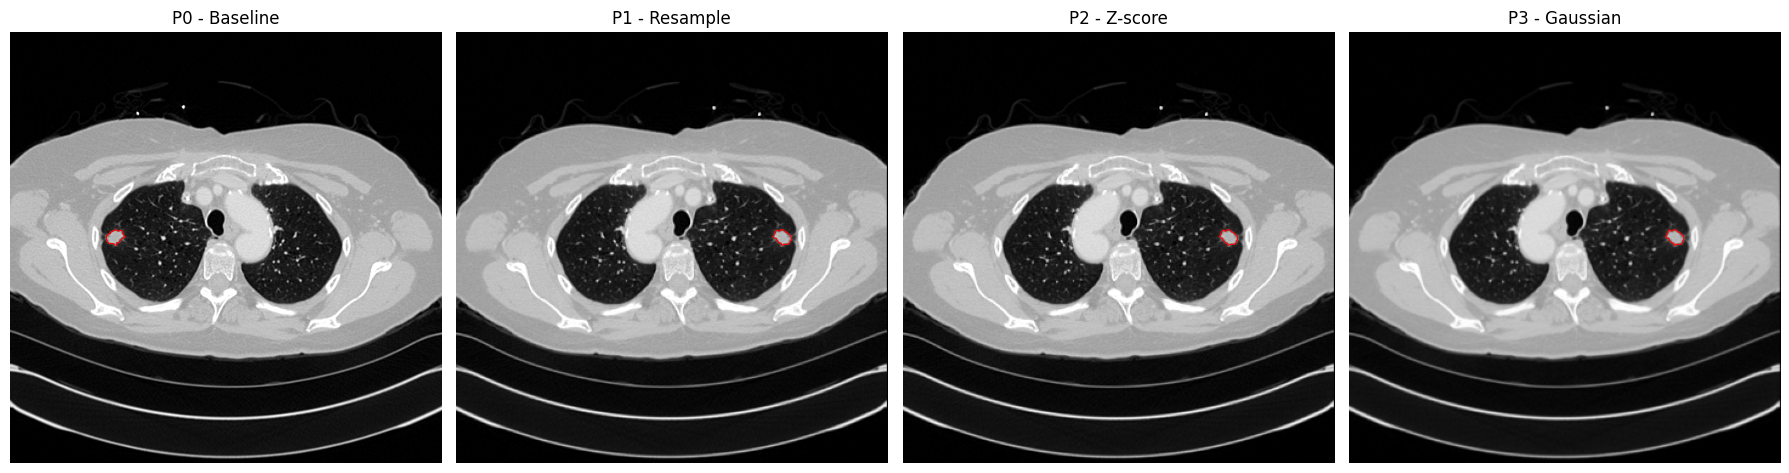

In [13]:
import matplotlib.pyplot as plt
import numpy as np

# Chọn lát cắt có diện tích khối u lớn nhất
tumor_area = mask_p3.sum(axis=(0, 1))
z = int(np.argmax(tumor_area))

print("Lát cắt được chọn:", z)
print("Số pixel khối u:", tumor_area[z])

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

images = [
    (ct_p0[:, :, z], mask_p0[:, :, z], "P0 - Baseline"),
    (ct_p1[:, :, z], mask_p3[:, :, z], "P1 - Resample"),
    (ct_p2[:, :, z], mask_p3[:, :, z], "P2 - Z-score"),
    (ct_p3[:, :, z], mask_p3[:, :, z], "P3 - Gaussian")
]

for ax, (image, mask_slice, title) in zip(axes, images):
    ax.imshow(image.T, cmap="gray", origin="lower")
    if mask_slice.sum() > 0:
        ax.contour(
            mask_slice.T,
            levels=[0.5],
            colors="red",
            linewidths=0.8,
            origin="lower"
        )
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [14]:
import os
import numpy as np
import pandas as pd
import nibabel as nib

from nibabel.processing import resample_to_output

BASE = '/content/drive/MyDrive/lung_project'
ROOT = '/content/data/Task06_Lung'

folds = pd.read_csv(
    f'{BASE}/splits/folds_seed42.csv'
)

# Tạo nơi lưu thống kê
OUTPUT_DIR = f'{BASE}/preprocessing'
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Lưu tổng theo từng Fold
fold_stats = {}

for fold_id in range(5):
    fold_stats[fold_id] = {
        'sum': 0.0,
        'sq_sum': 0.0,
        'count': 0
    }

# Xử lý từng ca đúng một lần
for i, row in folds.iterrows():

    case = row['case']
    assigned_fold = int(row['fold'])

    image_path = f'{ROOT}/imagesTr/{case}.nii.gz'

    img = nib.load(image_path)
    ct = img.get_fdata(dtype=np.float32)

    # P0: Clip HU và normalize
    ct = (np.clip(ct, -1000, 400) + 1000) / 1400

    # P1: Resample 1x1x1 mm
    ct_img = nib.Nifti1Image(ct, img.affine)

    ct_resampled = resample_to_output(
        ct_img,
        voxel_sizes=(1.0, 1.0, 1.0),
        order=1
    )

    arr = ct_resampled.get_fdata(dtype=np.float32)

    # Cộng thống kê vào Fold chứa ca này
    stats = fold_stats[assigned_fold]

    arr64 = arr.astype(np.float64)

    stats['sum'] += arr64.sum()
    stats['sq_sum'] += np.square(arr64).sum()
    stats['count'] += arr.size

    print(
        f'[{i+1}/63] {case} - Fold {assigned_fold} hoàn thành'
    )

# Tính tổng toàn bộ dữ liệu
total_sum = sum(x['sum'] for x in fold_stats.values())
total_sq_sum = sum(x['sq_sum'] for x in fold_stats.values())
total_count = sum(x['count'] for x in fold_stats.values())

# Tính mean/std riêng cho từng Fold
results = []

for fold_id in range(5):

    # Loại dữ liệu validation của Fold hiện tại
    val_stats = fold_stats[fold_id]

    train_sum = total_sum - val_stats['sum']
    train_sq_sum = total_sq_sum - val_stats['sq_sum']
    train_count = total_count - val_stats['count']

    mean = train_sum / train_count

    variance = train_sq_sum / train_count - mean**2
    std = np.sqrt(max(variance, 0.0))

    results.append({
        'fold': fold_id,
        'train_cases': int((folds['fold'] != fold_id).sum()),
        'val_cases': int((folds['fold'] == fold_id).sum()),
        'mean': mean,
        'std': std,
        'train_voxels': train_count
    })

stats_df = pd.DataFrame(results)

# Lưu CSV
stats_path = f'{OUTPUT_DIR}/zscore_stats_seed42.csv'
stats_df.to_csv(stats_path, index=False)

print("\n===== Z-SCORE STATISTICS =====")
display(stats_df)

print("\nĐã lưu:", stats_path)

[1/63] lung_001 - Fold 0 hoàn thành
[2/63] lung_003 - Fold 4 hoàn thành
[3/63] lung_004 - Fold 3 hoàn thành
[4/63] lung_005 - Fold 4 hoàn thành
[5/63] lung_006 - Fold 3 hoàn thành
[6/63] lung_009 - Fold 3 hoàn thành
[7/63] lung_010 - Fold 1 hoàn thành
[8/63] lung_014 - Fold 2 hoàn thành
[9/63] lung_015 - Fold 0 hoàn thành
[10/63] lung_016 - Fold 1 hoàn thành
[11/63] lung_018 - Fold 1 hoàn thành
[12/63] lung_020 - Fold 1 hoàn thành
[13/63] lung_022 - Fold 1 hoàn thành
[14/63] lung_023 - Fold 1 hoàn thành
[15/63] lung_025 - Fold 3 hoàn thành
[16/63] lung_026 - Fold 0 hoàn thành
[17/63] lung_027 - Fold 0 hoàn thành
[18/63] lung_028 - Fold 2 hoàn thành
[19/63] lung_029 - Fold 1 hoàn thành
[20/63] lung_031 - Fold 2 hoàn thành
[21/63] lung_033 - Fold 4 hoàn thành
[22/63] lung_034 - Fold 4 hoàn thành
[23/63] lung_036 - Fold 4 hoàn thành
[24/63] lung_037 - Fold 2 hoàn thành
[25/63] lung_038 - Fold 1 hoàn thành
[26/63] lung_041 - Fold 3 hoàn thành
[27/63] lung_042 - Fold 0 hoàn thành
[28/63] lu

,fold,train_cases,val_cases,mean,std,train_voxels
0,0,50,13,0.294048,0.334452,2813017594
1,1,50,13,0.291708,0.334845,2795528483
2,2,50,13,0.292421,0.333790,2713304583
3,3,51,12,0.290161,0.334161,2749950420
4,4,51,12,0.292583,0.334900,2750656652



Đã lưu: /content/drive/MyDrive/lung_project/preprocessing/zscore_stats_seed42.csv


In [ ]:
import os
import matplotlib.pyplot as plt

# Thư mục lưu hình ảnh
BASE = '/content/drive/MyDrive/lung_project'
FIG_DIR = f'{BASE}/results/figures'

os.makedirs(FIG_DIR, exist_ok=True)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

images = [
    (ct_p0[:, :, z], mask_p0[:, :, z], "P0 - Baseline"),
    (ct_p1[:, :, z], mask_p1[:, :, z], "P1 - Resample"),
    (ct_p2[:, :, z], mask_p1[:, :, z], "P2 - Z-score"),
    (ct_p3[:, :, z], mask_p3[:, :, z], "P3 - Gaussian")
]

for ax, (image, mask_slice, title) in zip(axes, images):
    ax.imshow(image.T, cmap="gray", origin="lower")

    if mask_slice.sum() > 0:
        ax.contour(
            mask_slice.T,
            levels=[0.5],
            colors="red",
            linewidths=0.8,
            origin="lower"
        )

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()

# Lưu hình
save_path = f'{FIG_DIR}/comparison_P0_P3_lung001.png'

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Đã lưu hình tại:", save_path)c

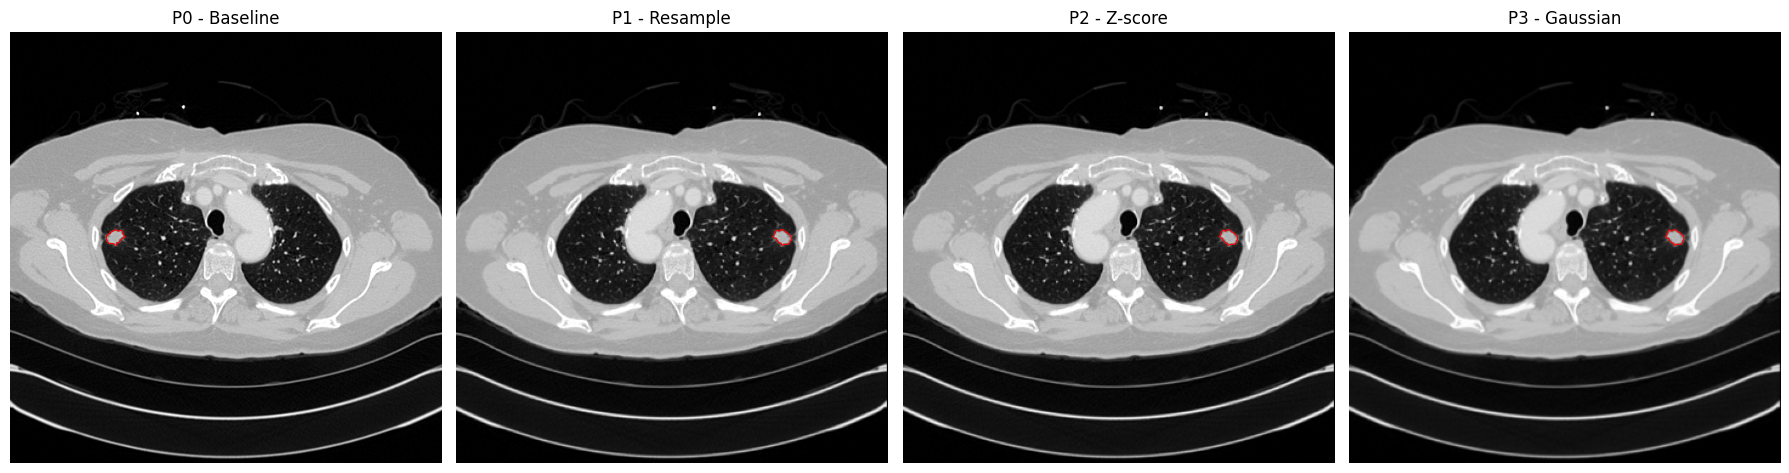

Đã lưu hình tại: /content/drive/MyDrive/lung_project/results/figures/comparison_P0_P3_lung001.png


In [15]:
import os
import matplotlib.pyplot as plt

# Thư mục lưu hình ảnh
BASE = '/content/drive/MyDrive/lung_project'
FIG_DIR = f'{BASE}/results/figures'

os.makedirs(FIG_DIR, exist_ok=True)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

images = [
    (ct_p0[:, :, z], mask_p0[:, :, z], "P0 - Baseline"),
    (ct_p1[:, :, z], mask_p1[:, :, z], "P1 - Resample"),
    (ct_p2[:, :, z], mask_p1[:, :, z], "P2 - Z-score"),
    (ct_p3[:, :, z], mask_p3[:, :, z], "P3 - Gaussian")
]

for ax, (image, mask_slice, title) in zip(axes, images):
    ax.imshow(image.T, cmap="gray", origin="lower")

    if mask_slice.sum() > 0:
        ax.contour(
            mask_slice.T,
            levels=[0.5],
            colors="red",
            linewidths=0.8,
            origin="lower"
        )

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()

# Lưu hình
save_path = f'{FIG_DIR}/comparison_P0_P3_lung001.png'

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Đã lưu hình tại:", save_path)